# **Custom GPU Compute Kernels for LLM Inference (Triton vs PyTorch)**

**Author:** Milana Sadokha

This notebook explores the implementation and benchmarking of custom GPU kernels using **OpenAI Triton**, comparing them against eager PyTorch and `torch.compile` on an NVIDIA T4.


In [23]:
import torch
import triton
import triton.language as tl
import triton.testing
from torch.profiler import profile, record_function, ProfilerActivity

# Reproducibility and environment logging
print(f"PyTorch version: {torch.__version__}")
print(f"Triton version: {triton.__version__}")
if torch.cuda.is_available():
    print(f"Hardware: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.11.0+cu130
Triton version: 3.6.0
Hardware: Tesla T4


## Part 1: SiLU (Swish) Activation Function
SiLU is an element-wise operation, making it strictly memory-bound.
**Conclusion:** Both implementations hit the T4 memory bandwidth wall (~228 GB/s). Triton achieves parity with highly optimized PyTorch ATen dispatch, while smaller sizes are constrained by kernel launch overhead.

In [24]:
@triton.jit
def silu_kernel(x_ptr, y_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    pid = tl.program_id(axis=0)
    block_start = pid * BLOCK_SIZE
    offsets = block_start + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements

    x = tl.load(x_ptr + offsets, mask=mask).to(tl.float32)
    sigmoid_x = 1.0 / (1.0 + tl.exp(-x))
    y = x * sigmoid_x

    y = y.to(y_ptr.dtype.element_ty)
    tl.store(y_ptr + offsets, y, mask=mask)

def triton_silu(x: torch.Tensor) -> torch.Tensor:
    assert x.is_cuda, "Triton only supports CUDA tensors"
    x_c = x.contiguous()
    y = torch.empty_like(x_c)
    n_elements = x.numel()

    grid = lambda meta: (triton.cdiv(n_elements, meta['BLOCK_SIZE']),)
    silu_kernel[grid](x_c, y, n_elements, BLOCK_SIZE=1024)
    return y.view_as(x)

x32 = torch.randn(5000, device='cuda', dtype=torch.float32)
torch.testing.assert_close(triton_silu(x32), torch.nn.functional.silu(x32), atol=1e-4, rtol=1e-4)

x16 = torch.randn(5000, device="cuda", dtype=torch.float16)
torch.testing.assert_close(triton_silu(x16), torch.nn.functional.silu(x16), atol=1e-3, rtol=1e-3)
print("SiLU correctness tests passed!")

SiLU correctness tests passed!


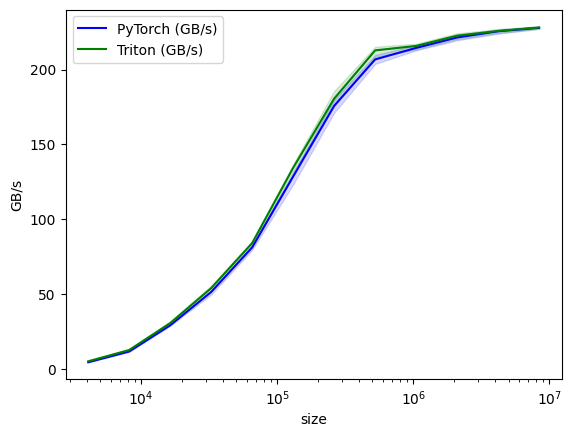

In [25]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['size'],
        x_vals=[2**i for i in range(12, 24)],
        x_log=True,
        line_arg='provider',
        line_vals=['torch', 'triton'],
        line_names=['PyTorch', 'Triton'],
        styles=[('blue', '-'), ('green', '-')],
        ylabel='GB/s',
        plot_name='silu-performance',
        args={},
    )
)
def benchmark_silu(size, provider):
    x = torch.randn(size, device='cuda', dtype=torch.float32)
    quantiles = [0.5, 0.2, 0.8]

    if provider == 'torch':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: torch.nn.functional.silu(x), quantiles=quantiles)
    if provider == 'triton':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: triton_silu(x), quantiles=quantiles)

    gbps = lambda ms: 2 * x.nelement() * x.element_size() * 1e-9 / (ms * 1e-3)
    return gbps(ms), gbps(max_ms), gbps(min_ms)

benchmark_silu.run(print_data=True, show_plots=True)

## Part 2: Fused LayerNorm
Layer Normalization requires a reduction across the hidden dimension.
**Initial Hypothesis:** Native PyTorch performs multiple reads/writes (launching multiple kernels) to store intermediate statistics for the backward pass, which throttles inference bandwidth. Our custom Triton kernel will load the row into on-chip registers once, compute statistics, and write back, increasing effective bandwidth. *(Note: This hypothesis is tested via profiler in Part 3).*

In [26]:
@triton.jit
def layernorm_kernel(
    x_ptr, y_ptr, weight_ptr, bias_ptr,
    stride_x_row, N, eps,
    BLOCK_SIZE: tl.constexpr
):
    row_idx = tl.program_id(0)
    row_start_ptr = x_ptr + row_idx * stride_x_row

    cols = tl.arange(0, BLOCK_SIZE)
    mask = cols < N

    # Load row to on-chip registers
    x = tl.load(row_start_ptr + cols, mask=mask, other=0.0).to(tl.float32)
    weight = tl.load(weight_ptr + cols, mask=mask).to(tl.float32)
    bias = tl.load(bias_ptr + cols, mask=mask).to(tl.float32)

    # Compute in registers
    mean = tl.sum(x, axis=0) / N
    x_centered = tl.where(mask, x - mean, 0.0)
    var = tl.sum(x_centered * x_centered, axis=0) / N

    x_hat = x_centered / tl.sqrt(var + eps)
    y = weight * x_hat + bias

    y_row_start_ptr = y_ptr + row_idx * stride_x_row
    y = y.to(y_ptr.dtype.element_ty)
    tl.store(y_row_start_ptr + cols, y, mask=mask)

def triton_layernorm(x, weight, bias, eps=1e-5):
    assert x.is_cuda and weight.is_cuda and bias.is_cuda
    x_c = x.contiguous()

    original_shape = x_c.shape
    N = original_shape[-1]
    x_2d = x_c.view(-1, N)
    M = x_2d.shape[0]

    y_2d = torch.empty_like(x_2d)
    BLOCK_SIZE = triton.next_power_of_2(N)

    # Assert against hardware limits
    max_block_size = 65536 // x.element_size()
    assert BLOCK_SIZE <= max_block_size, f"BLOCK_SIZE {BLOCK_SIZE} exceeds register/hardware limits"

    num_warps = min(max(BLOCK_SIZE // 256, 1), 8)
    grid = (M, )

    layernorm_kernel[grid](
        x_2d, y_2d, weight, bias,
        x_2d.stride(0), N, eps,
        num_warps=num_warps,
        BLOCK_SIZE=BLOCK_SIZE
    )
    return y_2d.view(original_shape)

for shape in [(4, 1024), (37, 1000), (2, 8, 512)]:
    N = shape[-1]
    x = torch.randn(shape, device="cuda", dtype=torch.float32)
    w = torch.randn(N, device="cuda", dtype=torch.float32)
    b = torch.randn(N, device="cuda", dtype=torch.float32)
    ref = torch.nn.functional.layer_norm(x, (N,), w, b, 1e-5)
    out_triton = triton_layernorm(x, w, b, eps=1e-5)
    torch.testing.assert_close(out_triton, ref, atol=1e-4, rtol=1e-4)

for N in [768, 1024, 2048, 3072, 4096, 8192]:
    M = 32
    x = torch.randn((M, N), device="cuda", dtype=torch.float16)
    w = torch.randn(N, device="cuda", dtype=torch.float16)
    b = torch.randn(N, device="cuda", dtype=torch.float16)
    ref = torch.nn.functional.layer_norm(x, (N,), w, b, 1e-5)
    out_triton = triton_layernorm(x, w, b, eps=1e-5)
    torch.testing.assert_close(out_triton, ref, atol=1e-2, rtol=1e-2)

Running FP32 structural tests...
Running FP16 benchmark-size tests...
LayerNorm correctness tests passed!


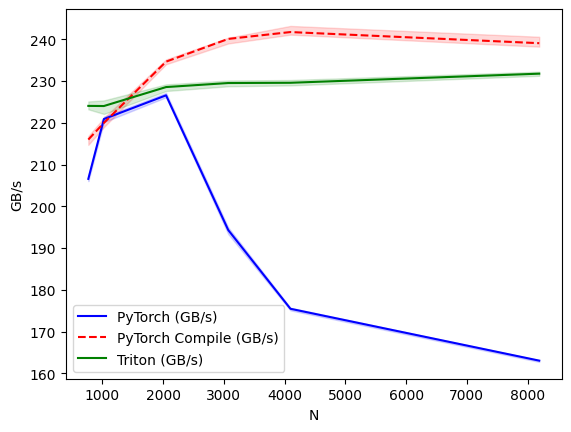

layernorm-performance-by-N:
        N  PyTorch (GB/s)  PyTorch Compile (GB/s)  Triton (GB/s)
0   768.0      206.571434              215.986819     224.045574
1  1024.0      220.899755              219.973155     224.013679
2  2048.0      226.578522              234.638029     228.553508
3  3072.0      194.312103              240.080580     229.520464
4  4096.0      175.477996              241.722044     229.579075
5  8192.0      163.061505              239.056841     231.760474


In [27]:
compiled_ln = torch.compile(torch.nn.functional.layer_norm, dynamic=False)

@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['N'],
        x_vals=[768, 1024, 2048, 3072, 4096, 8192],
        x_log=False,
        line_arg='provider',
        line_vals=['torch', 'torch_compile', 'triton'],
        line_names=['PyTorch', 'PyTorch Compile', 'Triton'],
        styles=[('blue', '-'), ('red', '--'), ('green', '-')],
        ylabel='GB/s',
        plot_name='layernorm-performance-by-N',
        args={'M': 4096},
    )
)
def benchmark_layernorm_n(M, N, provider):
    x = torch.randn(M, N, device='cuda', dtype=torch.float16)
    w = torch.randn(N, device='cuda', dtype=torch.float16)
    b = torch.randn(N, device='cuda', dtype=torch.float16)
    quantiles = [0.5, 0.2, 0.8]

    if provider == 'torch':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: torch.nn.functional.layer_norm(x, (N,), w, b), quantiles=quantiles)
    elif provider == 'torch_compile':
        compiled_ln(x, (N,), w, b)
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: compiled_ln(x, (N,), w, b), quantiles=quantiles)
    elif provider == 'triton':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: triton_layernorm(x, w, b), quantiles=quantiles)

    gb = (2 * M * N + 2 * N) * x.element_size() * 1e-9
    gbps = lambda ms: gb / (ms * 1e-3)
    return gbps(ms), gbps(max_ms), gbps(min_ms)

benchmark_layernorm_n.run(print_data=True, show_plots=True)

## Part 3: Profiler Validation
To verify the hypothesis from Part 2, we trace the CUDA kernel dispatches using the PyTorch profiler.
**Finding:** The profiler output disproves the initial hypothesis. Native PyTorch actually dispatches a single optimized kernel (`vectorized_layer_norm_kernel`) for the forward pass, meaning the performance gap is not caused by multiple kernel launches.

In [28]:
M, N = 4096, 4096
x = torch.randn(M, N, device='cuda', dtype=torch.float16)
w = torch.randn(N, device='cuda', dtype=torch.float16)
b = torch.randn(N, device='cuda', dtype=torch.float16)

for _ in range(3):
    torch.nn.functional.layer_norm(x, (N,), w, b)
    triton_layernorm(x, w, b)

print("Profiler: native pytorch")
with profile(activities=[ProfilerActivity.CUDA]) as prof_torch:
    with record_function("pytorch_layer_norm"):
        torch.nn.functional.layer_norm(x, (N,), w, b)
print(prof_torch.key_averages().table(sort_by="cuda_time_total", row_limit=5))

print("\nProfiler: triton")
with profile(activities=[ProfilerActivity.CUDA]) as prof_triton:
    with record_function("triton_layer_norm"):
        triton_layernorm(x, w, b)
print(prof_triton.key_averages().table(sort_by="cuda_time_total", row_limit=5))

Profile: native pytorch
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
void at::native::(anonymous namespace)::vectorized_l...         0.00%       0.000us         0.00%       0.000us       0.000us     377.431us       100.00%     377.431us     377.431us             1  
                                Activity Buffer Request        67.59%       1.852ms        67.59%       1.852ms       1.852ms       0.000us         0.00%       0.000us       0.000us  

*For full methodology, limitations, and future development steps, please refer to the `Conclusions` section in the repository's `README.md`.*